# ATAC-seq - Nutlin case

## Introduction

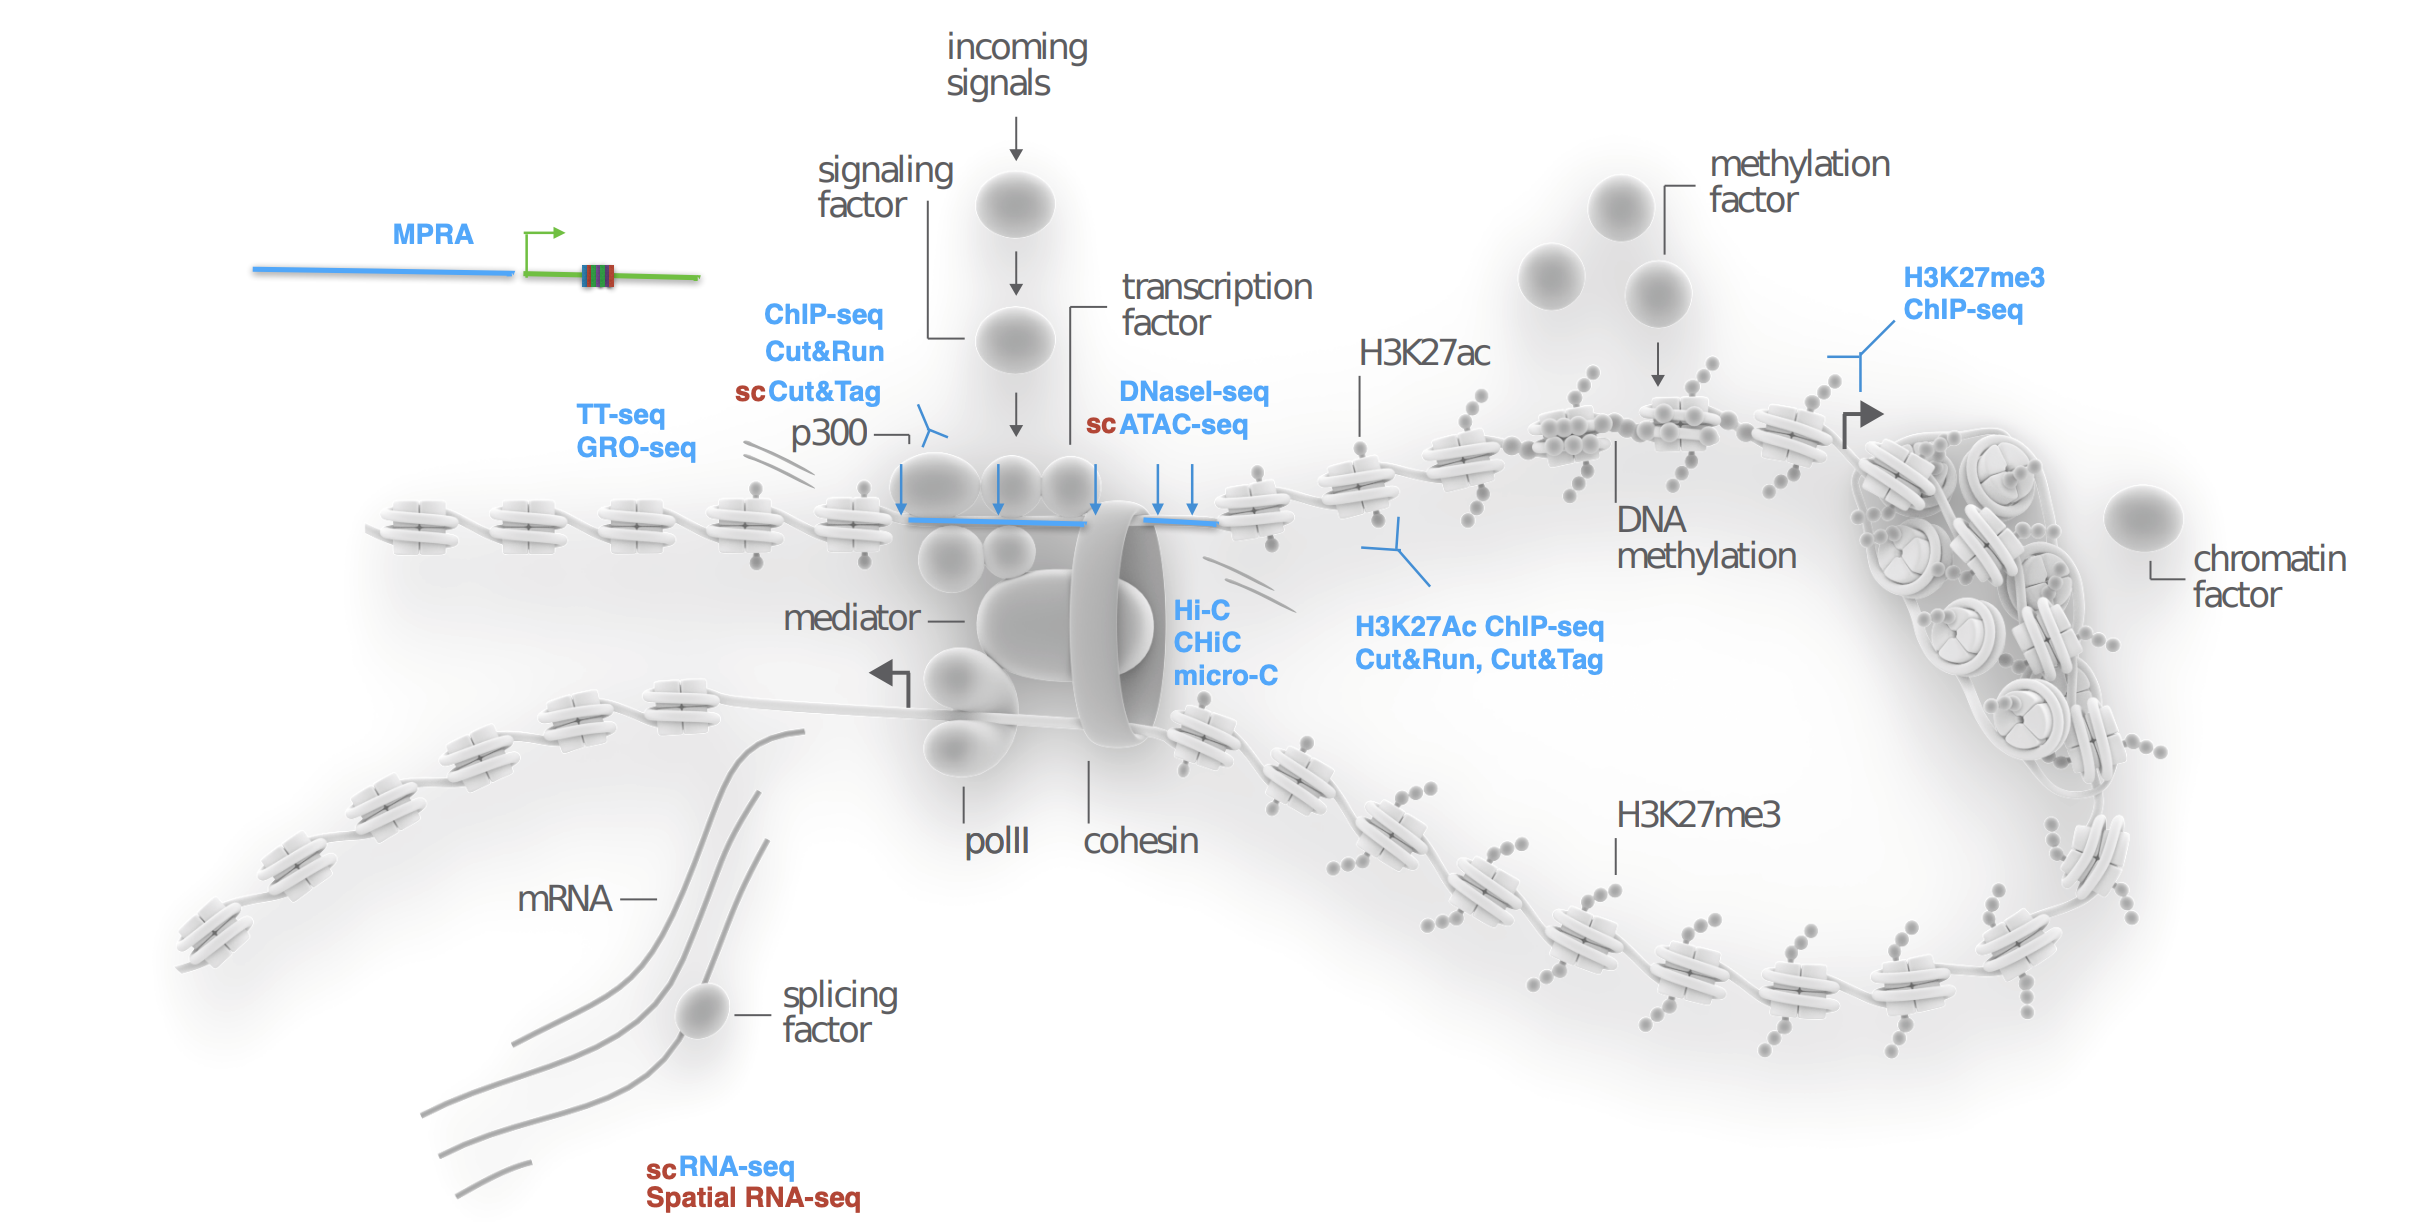

Gene regulation is a complex process that is regulated by a complex set of factors and sequences.

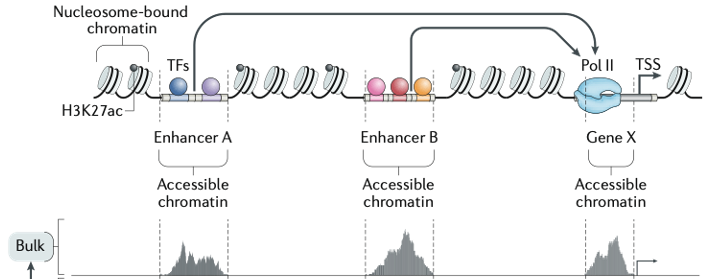

Minnoye et al., 2021

When transcription factors (TFs) and other factors bind the DNA, they displace nucleosomes and make the chromatin accessible.

ATAC-seq (Assay for Transposase-Accessible Chromatin) uses the Tn5 transposase to profile and sequence the accessible regions of the chromatin.

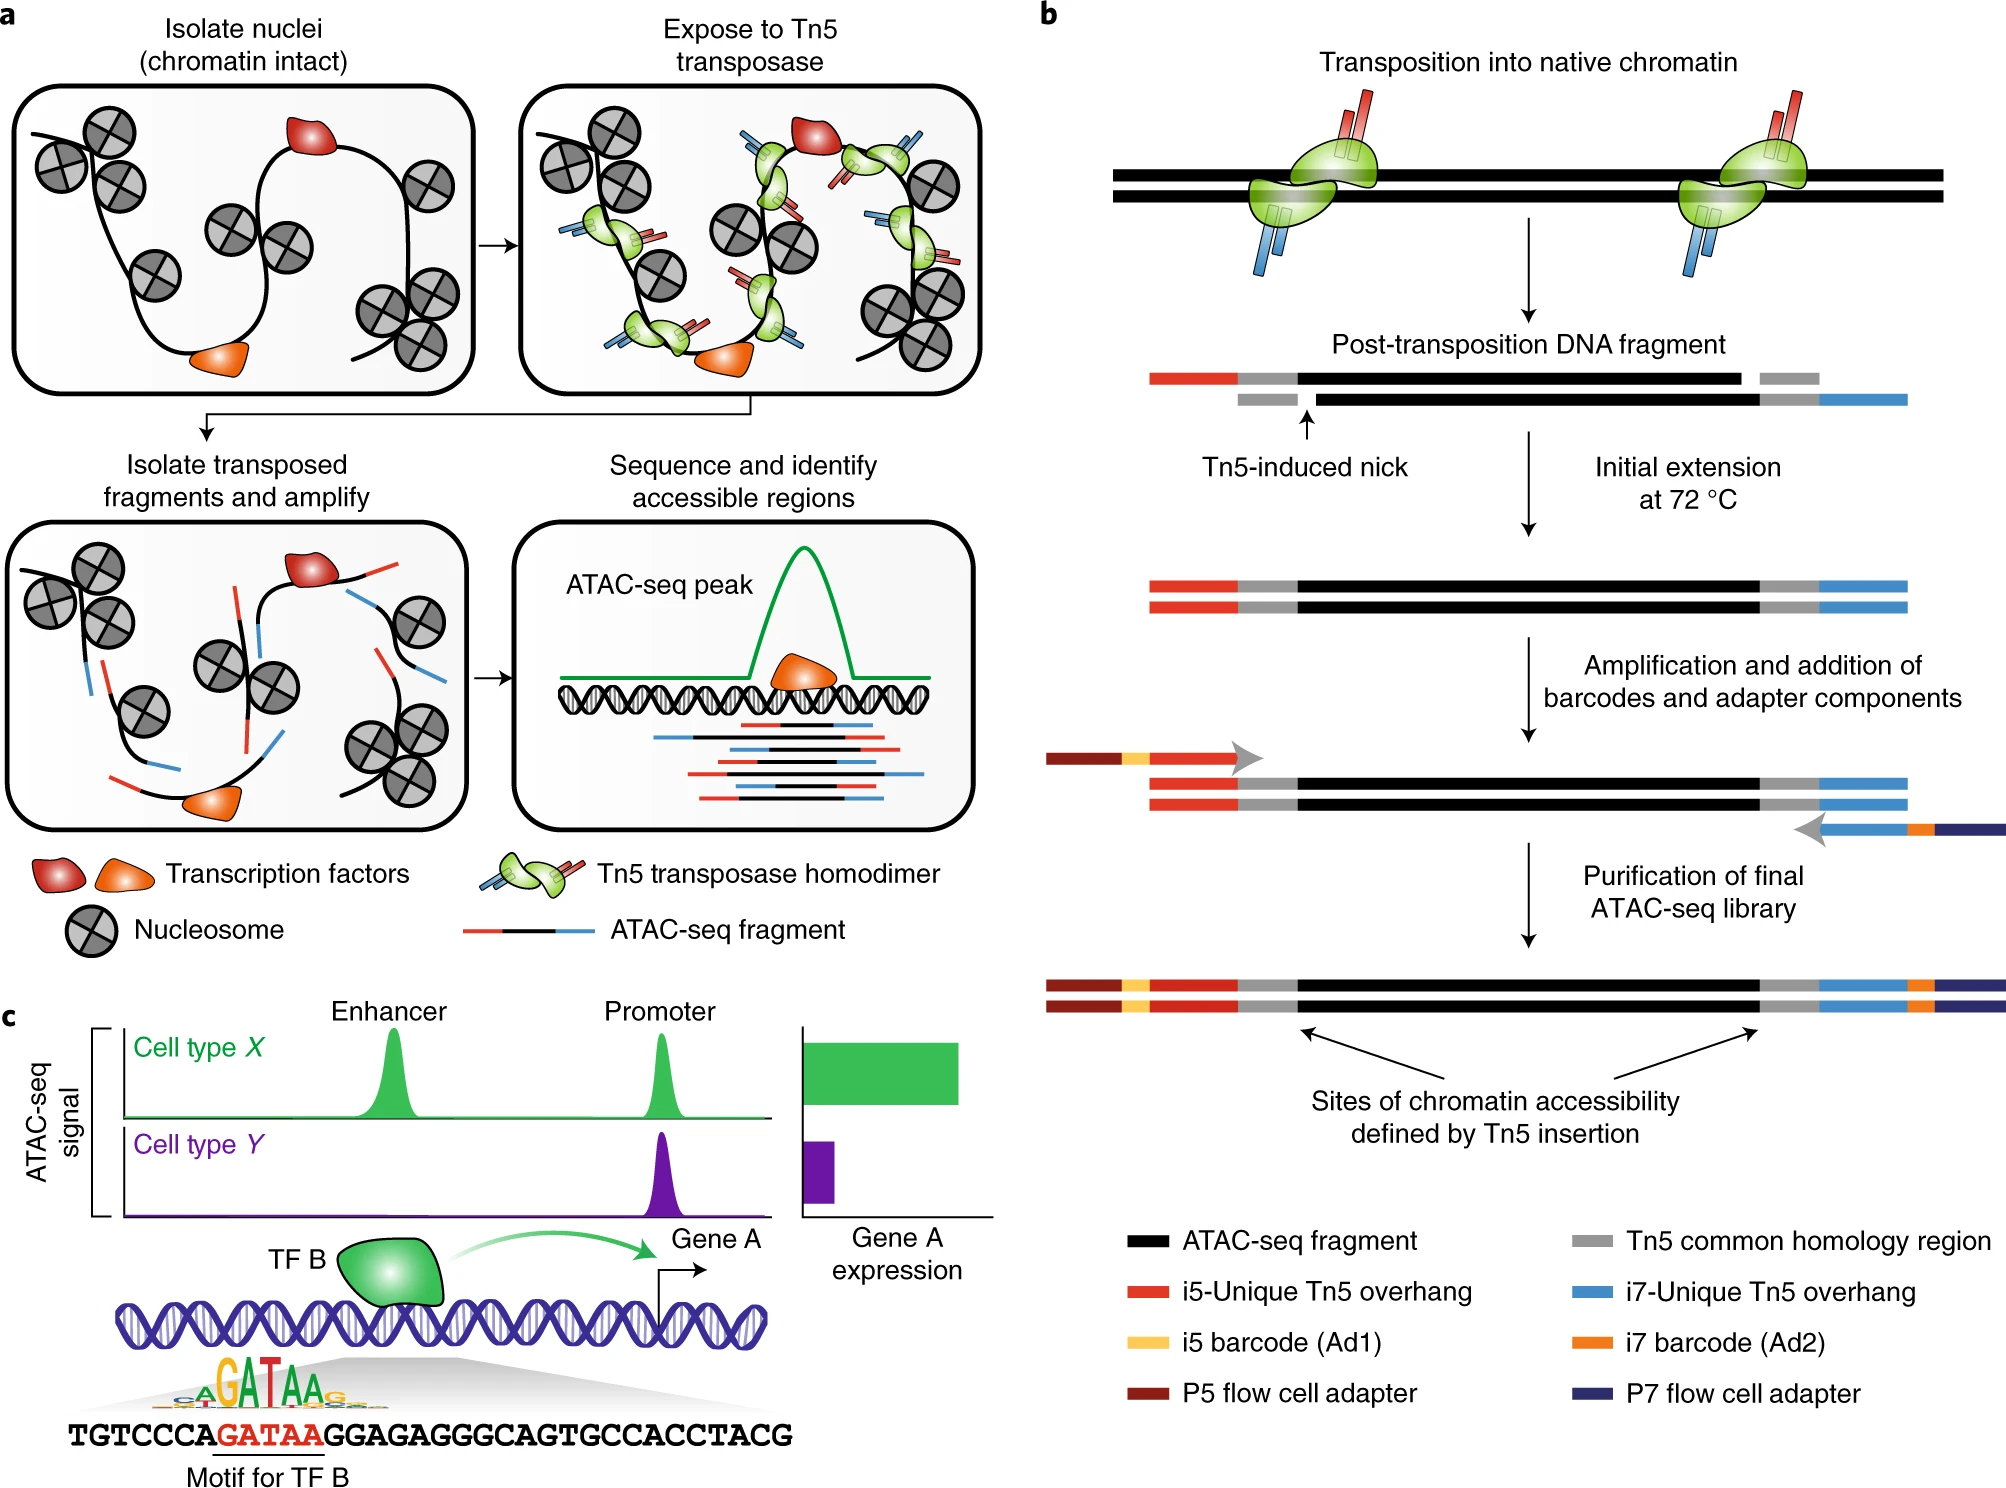

Grandi et al., 2022

Additional resources:

- [Harvard FAS Informatics - ATAC-seq Guidelines](https://github.com/harvardinformatics/ATAC-seq)
- [From reads to insight: a hitchhiker’s guide to ATAC-seq data analysis](https://genomebiology.biomedcentral.com/articles/10.1186/s13059-020-1929-3)
- https://yiweiniu.github.io/blog/2019/03/ATAC-seq-data-analysis-from-FASTQ-to-peaks/
- https://vallierlab.wixsite.com/pipelines/atac-seq
- [ENCODE ATAC-seq pipeline](https://github.com/ENCODE-DCC/atac-seq-pipeline)

## Analysis

We will analyse ATAC-seq data, related to TP53 activation.

The following publicly available record at GEO https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE58740 contains several epigenomic data sets related to TP53 activation. The treatment is similar to our previous case study, using nutlin-3a. However, here they used IMR90 normal cells, compared to the MCF-7 breast cancer cells we used previously.

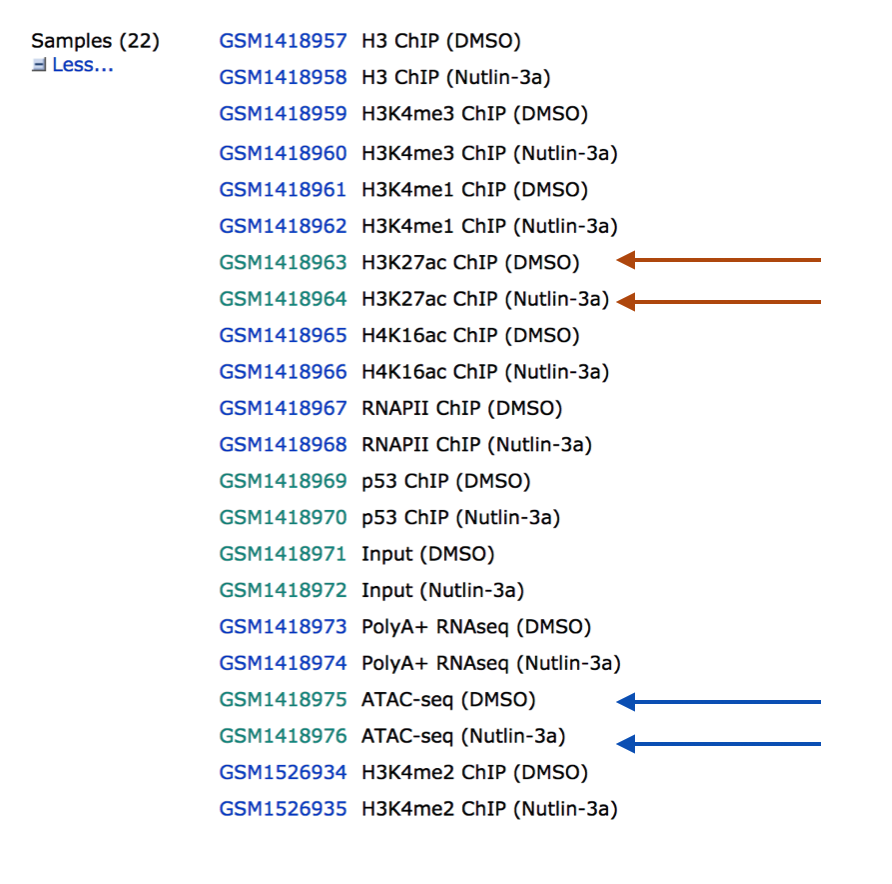

Let's create a directory for our analysis.

In [1]:
mkdir -p /data/user/$USER/atacseq/p53_nutlin
cd /data/user/$USER/atacseq/p53_nutlin

### Retrieval of fastq files

If you follow the links to two ATAC-seq datasets seen above, you can find the relevant SRR codes to retrieve the fastq files. Here are the codes:

SRR1448793 -> ATAC-seq (DMSO)

SRR1448795 -> ATAC-seq (Nutlin-3a)

Using this code, you can download the full data, although it is very big so we will skip that now:

In [ ]:
# prefetch SRR1448793
# fasterq-dump --threads 8 --progress SRR1448793

In [ ]:
# prefetch SRR1448795
# fasterq-dump --threads 8 --progress SRR1448795

### Alignment of fastq files

After retrieving our fastq files, we can align them to our genome. This step is computationally expensive, so we will only use the reads in chromosome 19. Note that we are doing this just as an example and in general it's not a very good idea to do the mapping partially like this since there's a discrepency between our genome files and reads. 

In [ ]:
# This is to get the full alignment
# bowtie2 -p 16 -x /data/teachers/data/genomes/hg19/bowtie2/hg19 SRR1448793.fastq | samtools view -u | samtools sort -@ 2 -o SRR1448793.bam
# bowtie2 -p 16 -x /data/teachers/data/genomes/hg19/bowtie2/hg19 SRR1448795.fastq | samtools view -u | samtools sort -@ 2 -o SRR1448795.bam

In [2]:
ln -sf /data/teachers/data/bulk_atac_seq/p53_nutlin/*.chr19.fastq ./

In [3]:
ls *.chr19.fastq

SRR1448793.chr19.fastq	SRR1448795.chr19.fastq


#### Untreated sample

In [4]:
fastqc SRR1448793.chr19.fastq

null
Started analysis of SRR1448793.chr19.fastq
Approx 5% complete for SRR1448793.chr19.fastq
Approx 10% complete for SRR1448793.chr19.fastq
Approx 15% complete for SRR1448793.chr19.fastq
Approx 20% complete for SRR1448793.chr19.fastq
Approx 25% complete for SRR1448793.chr19.fastq
Approx 30% complete for SRR1448793.chr19.fastq
Approx 35% complete for SRR1448793.chr19.fastq
Approx 40% complete for SRR1448793.chr19.fastq
Approx 45% complete for SRR1448793.chr19.fastq
Approx 50% complete for SRR1448793.chr19.fastq
Approx 55% complete for SRR1448793.chr19.fastq
Approx 60% complete for SRR1448793.chr19.fastq
Approx 65% complete for SRR1448793.chr19.fastq
Approx 70% complete for SRR1448793.chr19.fastq
Approx 75% complete for SRR1448793.chr19.fastq
Approx 80% complete for SRR1448793.chr19.fastq
Approx 85% complete for SRR1448793.chr19.fastq
Approx 90% complete for SRR1448793.chr19.fastq
Approx 95% complete for SRR1448793.chr19.fastq
Analysis complete for SRR1448793.chr19.fastq


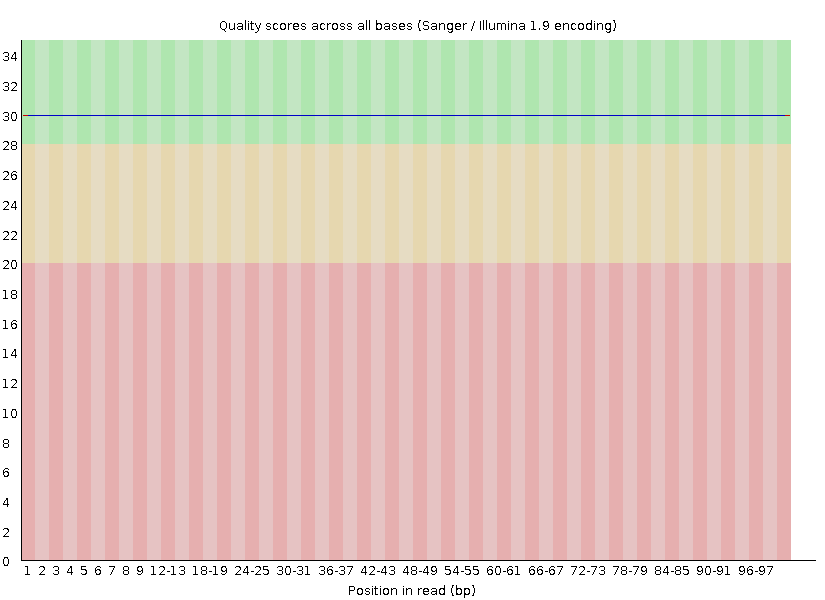

In [5]:
bowtie2 -p 8 -x /data/teachers/data/genomes/hg19/bowtie2/hg19 SRR1448793.chr19.fastq | samtools view -u | samtools sort -@ 2 -o SRR1448793.chr19.bam

1253351 reads; of these:
  1253351 (100.00%) were unpaired; of these:
    123819 (9.88%) aligned 0 times
    896406 (71.52%) aligned exactly 1 time
    233126 (18.60%) aligned >1 times
90.12% overall alignment rate
[bam_sort_core] merging from 0 files and 2 in-memory blocks...


In [6]:
wc -l SRR1448793.chr19.fastq | awk '{ print $1/4 }'

1253351


In [7]:
samtools view -c SRR1448793.chr19.bam

1253351


In [8]:
samtools flagstat SRR1448793.chr19.bam

1253351 + 0 in total (QC-passed reads + QC-failed reads)
1253351 + 0 primary
0 + 0 secondary
0 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
1129532 + 0 mapped (90.12% : N/A)
1129532 + 0 primary mapped (90.12% : N/A)
0 + 0 paired in sequencing
0 + 0 read1
0 + 0 read2
0 + 0 properly paired (N/A : N/A)
0 + 0 with itself and mate mapped
0 + 0 singletons (N/A : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a different chr (mapQ>=5)


In [9]:
samtools view -b -h -F 260 SRR1448793.chr19.bam -o SRR1448793.chr19.filtered.bam

To be able to view the resulting file in IGV, we have to create a index file using the following code, which will have a .bam.bai extension.

In [10]:
samtools sort -O bam -o SRR1448793.chr19.sorted.bam SRR1448793.chr19.filtered.bam

In [11]:
samtools index SRR1448793.chr19.sorted.bam

In [12]:
ls *.bam*

SRR1448793.chr19.bam	       SRR1448793.chr19.sorted.bam
SRR1448793.chr19.filtered.bam  SRR1448793.chr19.sorted.bam.bai


In [13]:
# Remove the bam files that we don't need anymore
rm SRR1448793.chr19.bam
rm SRR1448793.chr19.filtered.bam

Checking the BAM files in IGV

Now you can download the bam and the index (bam.bai) file to visualize your results in IGV. Here's an example of how it should look:

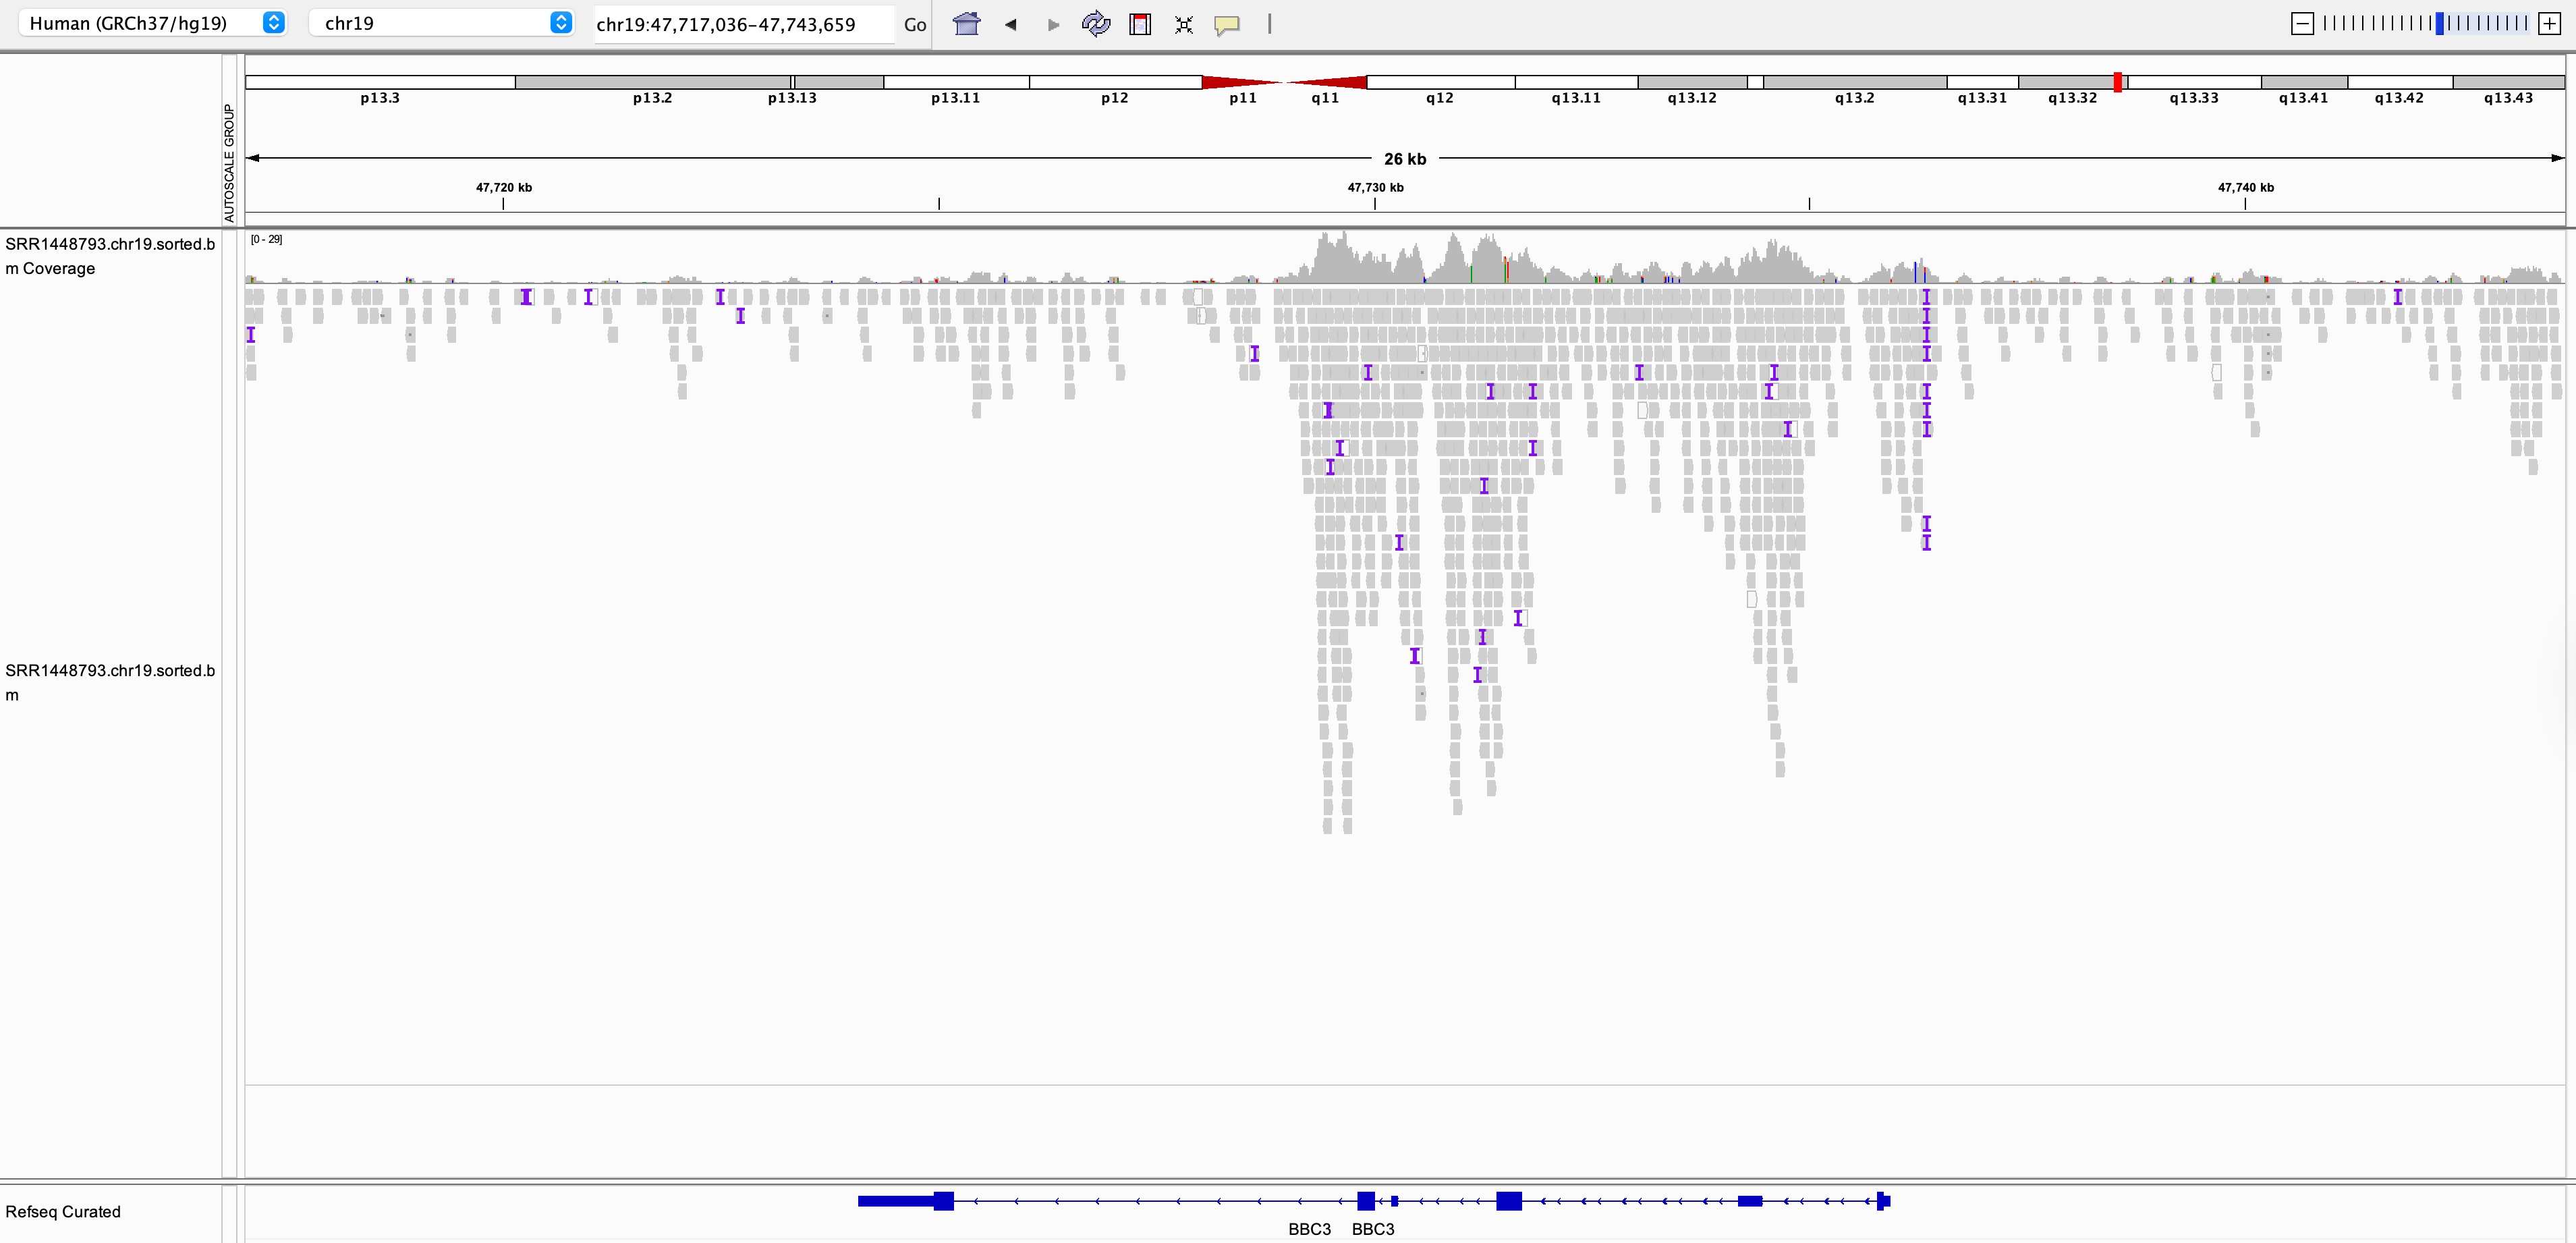

#### Treated sample

In [15]:
fastqc SRR1448795.chr19.fastq

null
Started analysis of SRR1448795.chr19.fastq
Approx 5% complete for SRR1448795.chr19.fastq
Approx 10% complete for SRR1448795.chr19.fastq
Approx 15% complete for SRR1448795.chr19.fastq
Approx 20% complete for SRR1448795.chr19.fastq
Approx 25% complete for SRR1448795.chr19.fastq
Approx 30% complete for SRR1448795.chr19.fastq
Approx 35% complete for SRR1448795.chr19.fastq
Approx 40% complete for SRR1448795.chr19.fastq
Approx 45% complete for SRR1448795.chr19.fastq
Approx 50% complete for SRR1448795.chr19.fastq
Approx 55% complete for SRR1448795.chr19.fastq
Approx 60% complete for SRR1448795.chr19.fastq
Approx 65% complete for SRR1448795.chr19.fastq
Approx 70% complete for SRR1448795.chr19.fastq
Approx 75% complete for SRR1448795.chr19.fastq
Approx 80% complete for SRR1448795.chr19.fastq
Approx 85% complete for SRR1448795.chr19.fastq
Approx 90% complete for SRR1448795.chr19.fastq
Approx 95% complete for SRR1448795.chr19.fastq
Analysis complete for SRR1448795.chr19.fastq


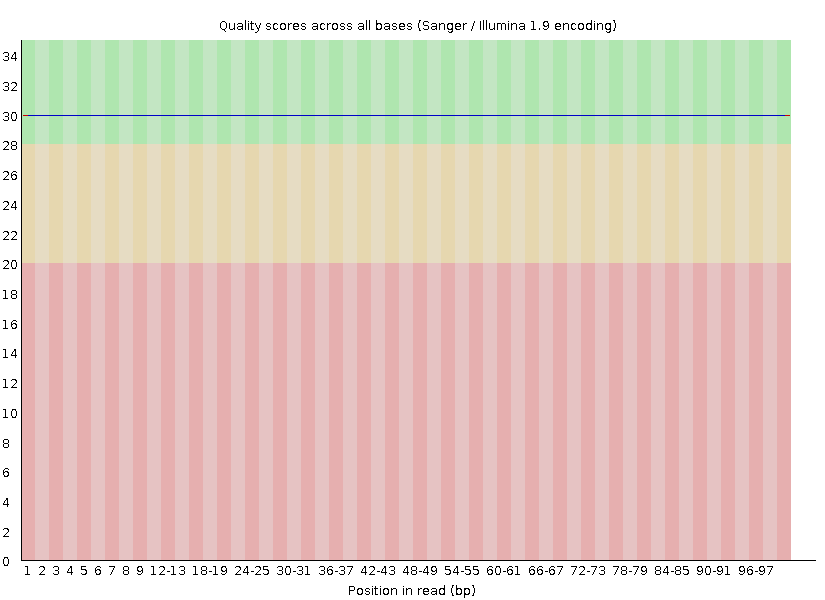

In [16]:
bowtie2 -p 8 -x /data/teachers/data/genomes/hg19/bowtie2/hg19 SRR1448795.chr19.fastq | samtools view -u | samtools sort -@ 2 -o SRR1448795.chr19.bam

1016443 reads; of these:
  1016443 (100.00%) were unpaired; of these:
    83131 (8.18%) aligned 0 times
    734304 (72.24%) aligned exactly 1 time
    199008 (19.58%) aligned >1 times
91.82% overall alignment rate
[bam_sort_core] merging from 0 files and 2 in-memory blocks...


In [17]:
wc -l SRR1448795.chr19.fastq | awk '{ print $1/4 }'

1016443


In [18]:
samtools view -c SRR1448795.chr19.bam

1016443


In [19]:
samtools flagstat SRR1448795.chr19.bam

1016443 + 0 in total (QC-passed reads + QC-failed reads)
1016443 + 0 primary
0 + 0 secondary
0 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
933312 + 0 mapped (91.82% : N/A)
933312 + 0 primary mapped (91.82% : N/A)
0 + 0 paired in sequencing
0 + 0 read1
0 + 0 read2
0 + 0 properly paired (N/A : N/A)
0 + 0 with itself and mate mapped
0 + 0 singletons (N/A : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a different chr (mapQ>=5)


In [20]:
samtools view -b -h -F 260 SRR1448795.chr19.bam -o SRR1448795.chr19.filtered.bam

To be able to view the resulting file in IGV, we have to create a index file using the following code, which will have a .bam.bai extension.

In [21]:
samtools sort -O bam -o SRR1448795.chr19.sorted.bam SRR1448795.chr19.filtered.bam

In [22]:
samtools index SRR1448795.chr19.sorted.bam

In [23]:
ls *.bam*

SRR1448793.chr19.sorted.bam	 SRR1448795.chr19.filtered.bam
SRR1448793.chr19.sorted.bam.bai  SRR1448795.chr19.sorted.bam
SRR1448795.chr19.bam		 SRR1448795.chr19.sorted.bam.bai


In [24]:
# Remove the bam files that we don't need anymore
rm SRR1448795.chr19.bam
rm SRR1448795.chr19.filtered.bam

The generated files can now be downloaded and visualized in IGV

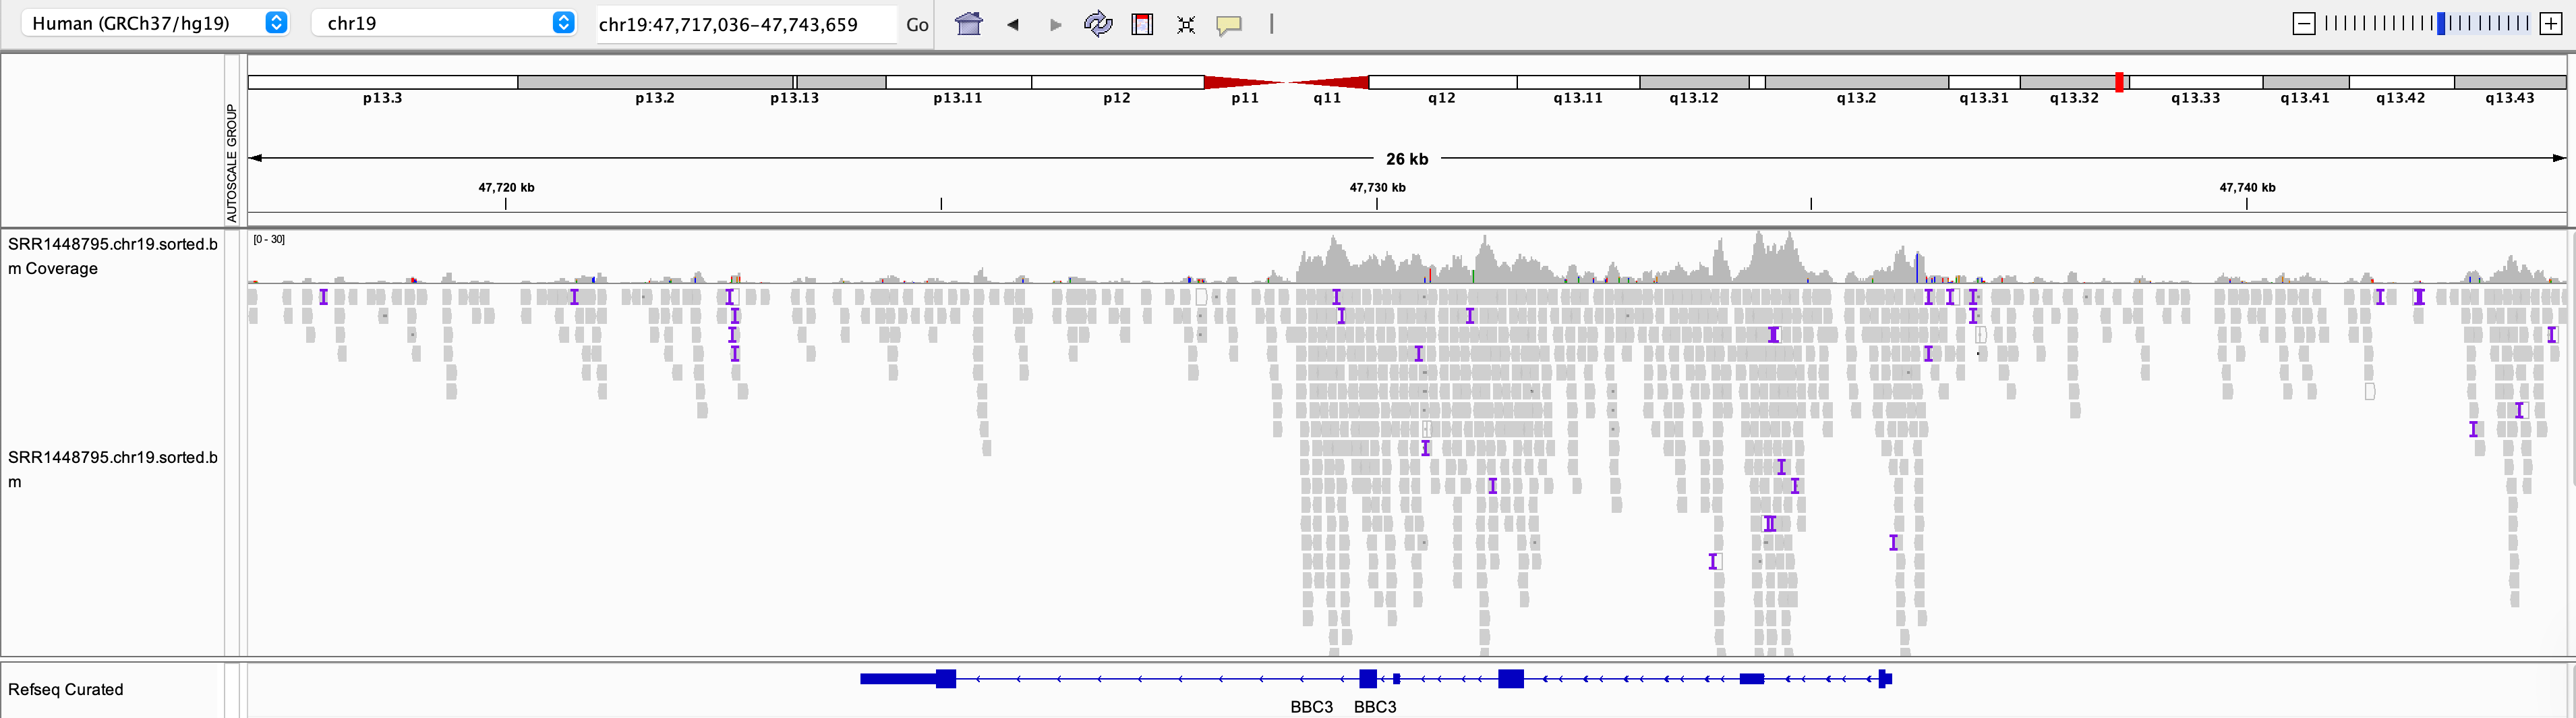

#### Both conditions

Now that we have the files for both conditions, we can load them together and try to see if we can find differences. Don't forget that there are some caveats here, first if you don't group autoscale your tracks, the y axis for each track will be different (you can do the scaling by selecting both tracks, right click, group autoscale). If you do that, keep in mind that in the case of data that is not normalized to read depth, your peaks will be biased. You can try autoscaling in that case (not group autoscale). Try all of it out now and notice how the same data looks in different cases:

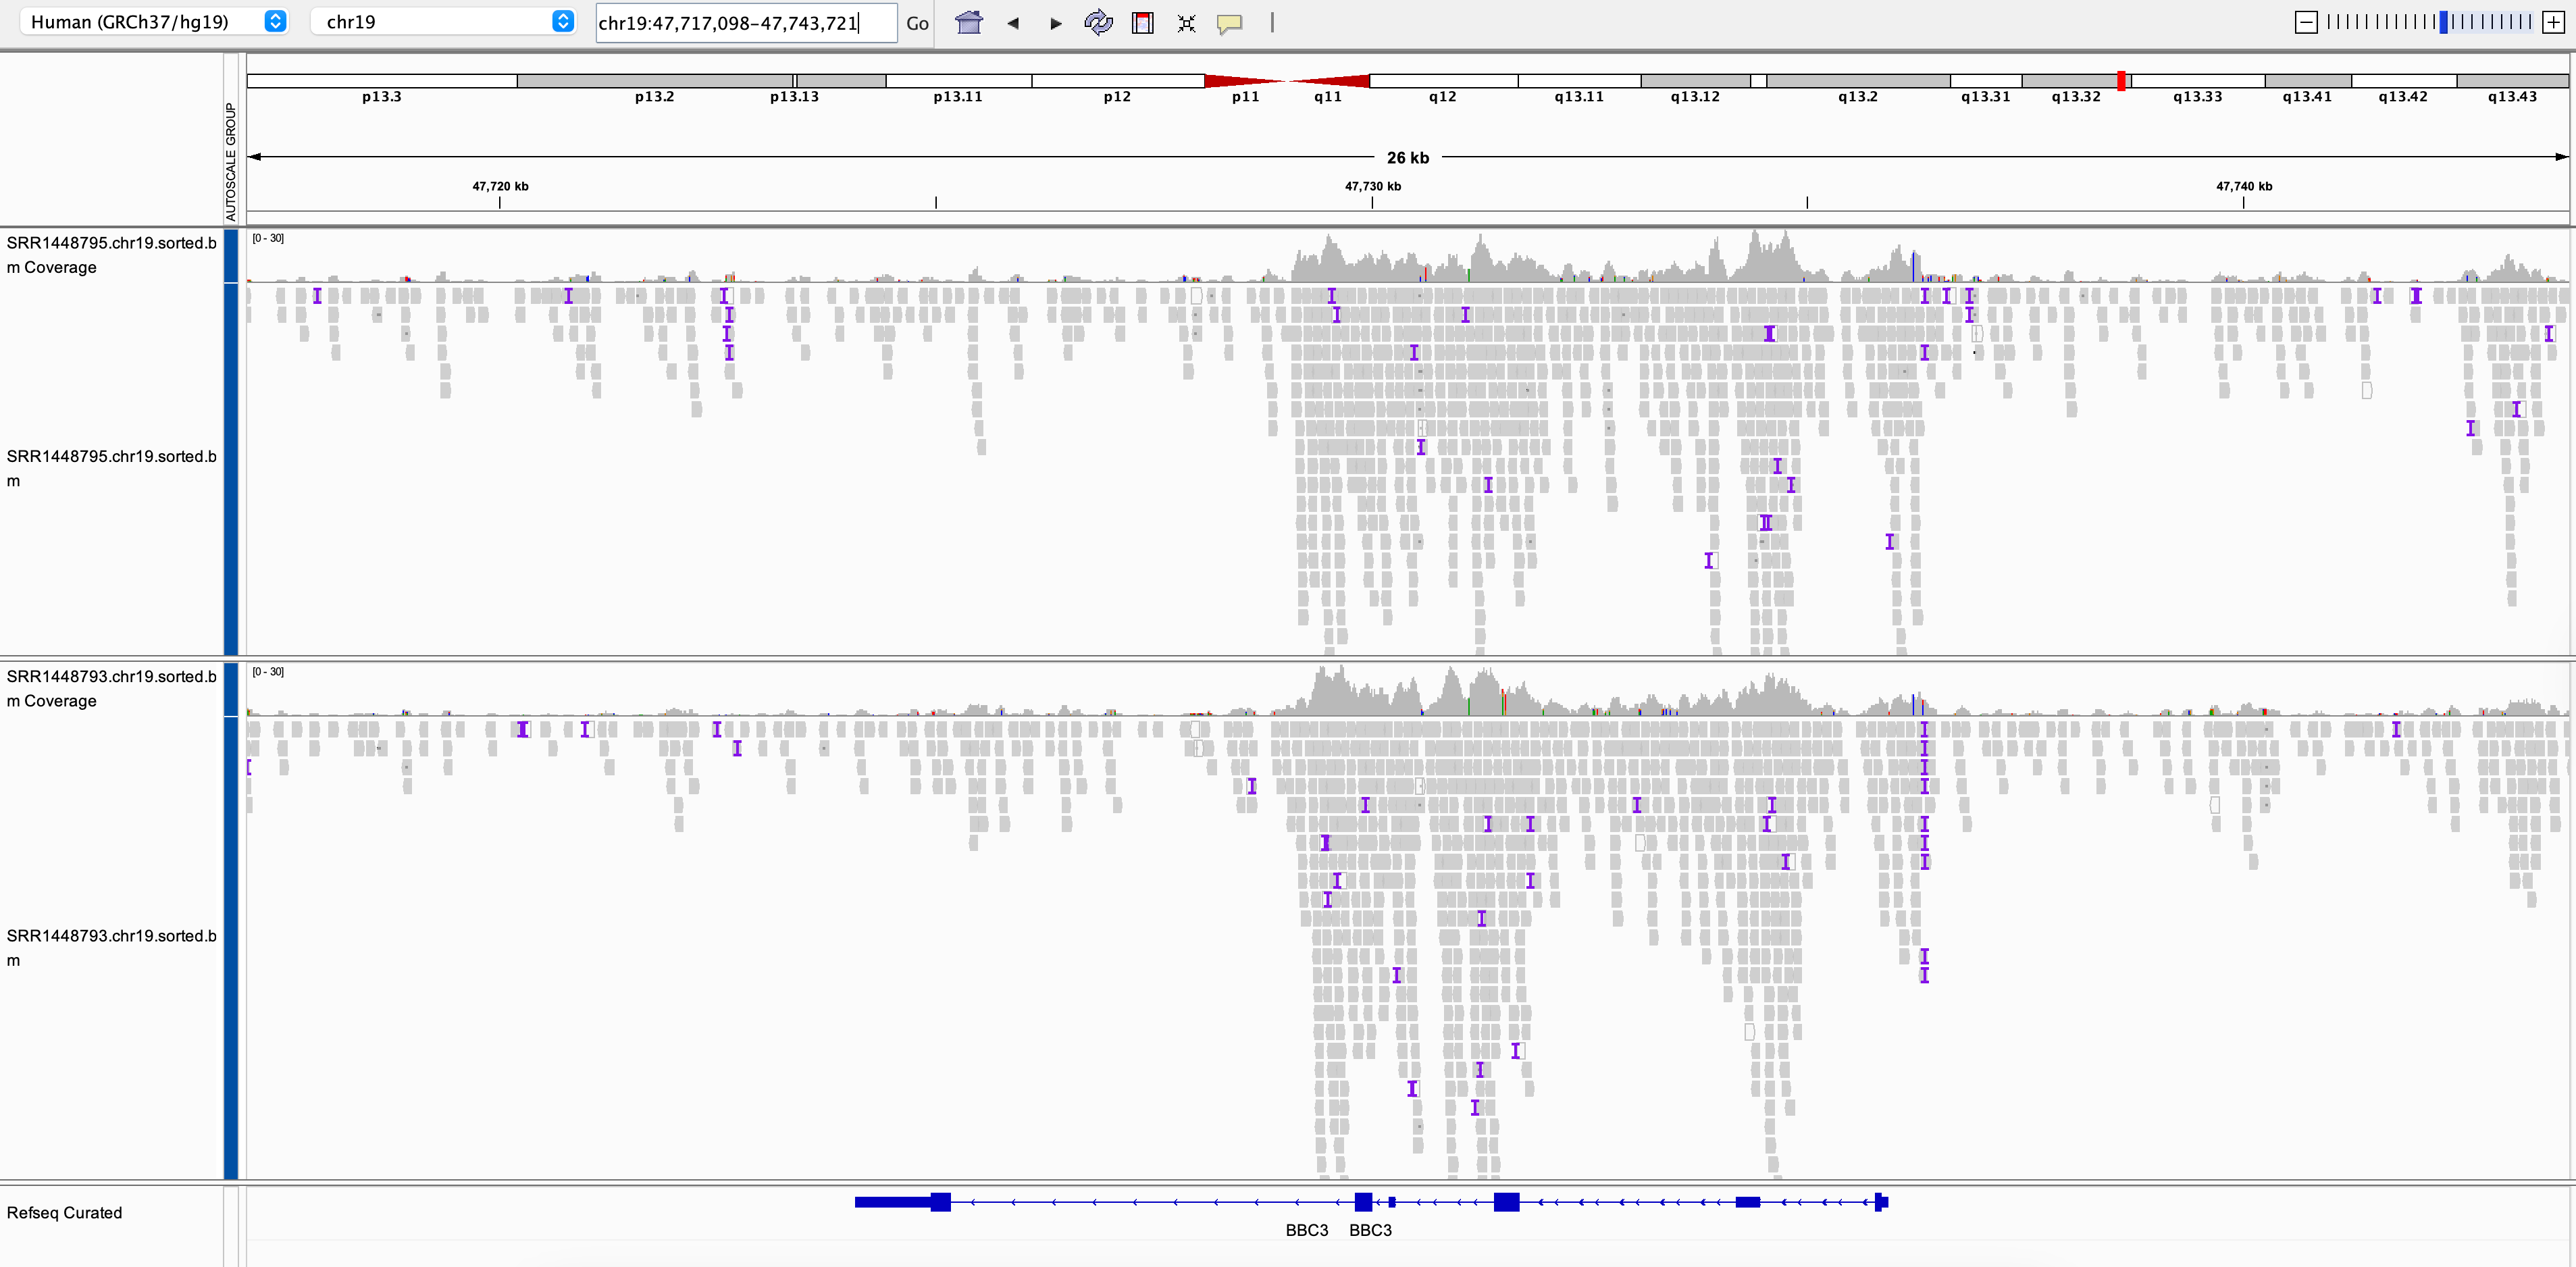

### BAM file of the whole genome

You can also have a look at how the BAM file of the whole genome looks like.

To get the already generated bam and index files:

In [ ]:
mkdir data_generated

In [31]:
ln -sf /data/teachers/data/bulk_atac_seq/p53_nutlin/data_generated/* ./data_generated/

Now you can see a folder named data_generated, where you can download the files SRR1448793.bam / SRR1448793.bam.bai and SRR1448795.bam / SRR1448795.bam.bai and visualize them in IGV. This way, you can also look at all the chromosomes instead of just chr19.

You can also compare this with your own alignment to see how similar it is (it should be similar but not necessarily identical).

### Genome Coverage

Now we can also generate genome coverage files, they will look similiar to (but not identical) the coverage track we have in our bam files.

These files are used to visualize your data in IGV or UCSC. You can download the bigwig files by following the links that we used to get the SRR codes before (https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE58740).

You don't have to do that now since we have already downloaded the files, which you can find again in your data_generated folder.

Next step in our analysis is to do peak calling, which we will see an example of later in the notebook.

It's also a good exercise to generate the coverage files ourselves and compare it with the provided ones. For that you can use the code below. Note that the -bs argument (bin size) is quite high here so we will get a coarse looking coverage file. This is done here to decrease the compute time but it's usually a better idea to use a lower bin size in your own work (5 might be a good place to start).

In [26]:
bamCoverage -b SRR1448793.chr19.sorted.bam --normalizeUsing RPGC --effectiveGenomeSize 59128983 -o SRR1448793.chr19.bw -bs 50

normalization: 1x (effective genome size 59128983)
bamFilesList: ['SRR1448793.chr19.sorted.bam']
binLength: 50
numberOfSamples: None
blackListFileName: None
skipZeroOverZero: False
bed_and_bin: False
genomeChunkSize: None
defaultFragmentLength: read length
numberOfProcessors: 1
verbose: False
region: None
bedFile: None
minMappingQuality: None
ignoreDuplicates: False
chrsToSkip: []
stepSize: 50
center_read: False
samFlag_include: None
samFlag_exclude: None
minFragmentLength: 0
maxFragmentLength: 0
zerosToNans: False
smoothLength: None
save_data: False
out_file_for_raw_data: None
maxPairedFragmentLength: 1000


In [27]:
bamCoverage -b SRR1448795.chr19.sorted.bam --normalizeUsing RPGC --effectiveGenomeSize 59128983 -o SRR1448795.chr19.bw -bs 50

normalization: 1x (effective genome size 59128983)
bamFilesList: ['SRR1448795.chr19.sorted.bam']
binLength: 50
numberOfSamples: None
blackListFileName: None
skipZeroOverZero: False
bed_and_bin: False
genomeChunkSize: None
defaultFragmentLength: read length
numberOfProcessors: 1
verbose: False
region: None
bedFile: None
minMappingQuality: None
ignoreDuplicates: False
chrsToSkip: []
stepSize: 50
center_read: False
samFlag_include: None
samFlag_exclude: None
minFragmentLength: 0
maxFragmentLength: 0
zerosToNans: False
smoothLength: None
save_data: False
out_file_for_raw_data: None
maxPairedFragmentLength: 1000


Downloaded bigWig files can be opened in IGV, it's a good idea to also load the H3K27Ac coverage files that you have used before and observe how it differs from ATAC-seq data:

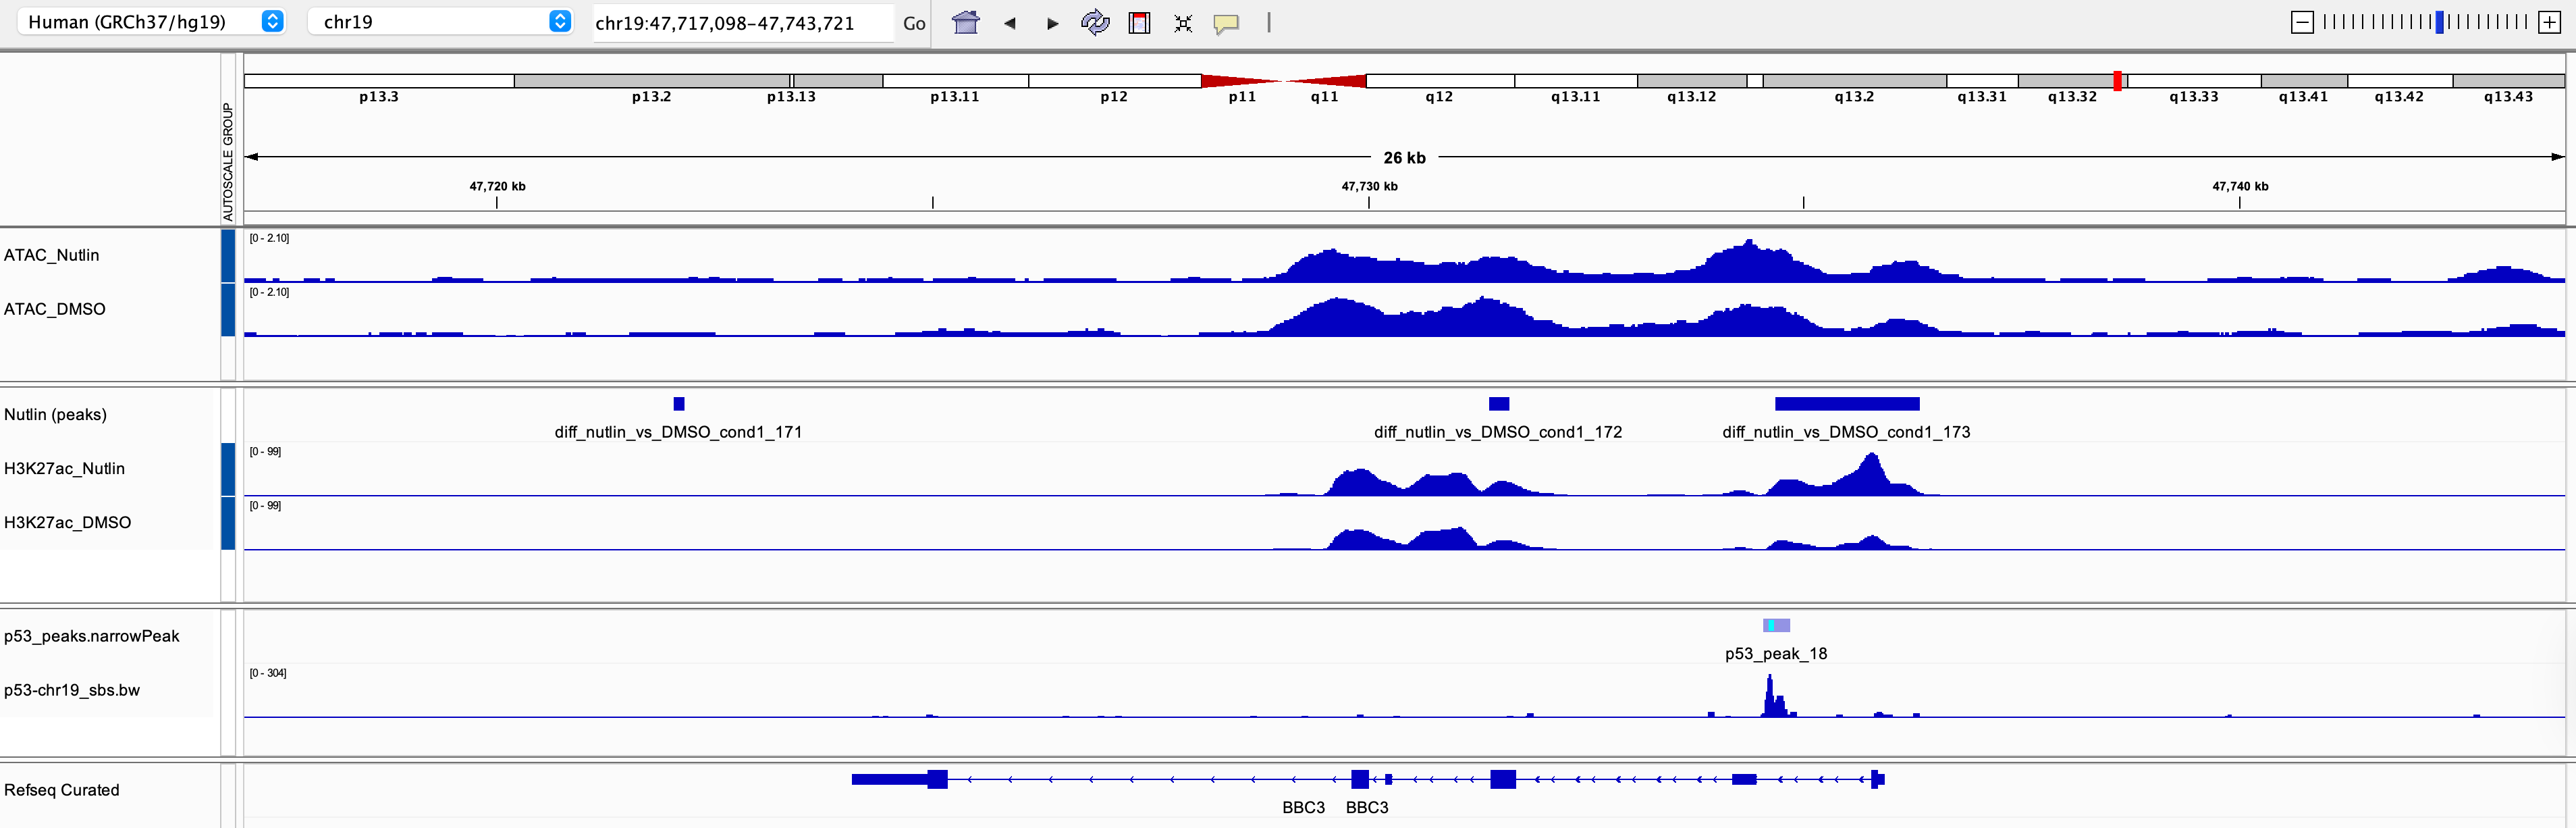

The peak in the BBC3 gene does not show obvious changes in ATAC and a slight change in H3K27Ac between DMSO-treated versus nutlin-treated cells.

You can add the coverage files you have generated to the same IGV sessions and compare them with the provided ones. Browse chr19 on IGV, keeping in mind where you see differences 1) between your control and treatment conditions 2) between the files you have generated and what was provided.

## Visualize ATAC-seq data on the TP53 ChIP-seq peaks

After downloading the bigWig files (you don't have to do this for this exercise, we already downloaded them)

Creat a symbolic link to the bigWig files on the server

In [34]:
ln -sf /data/teachers/data/bulk_atac_seq/p53_nutlin/data_generated/*.bigWig .

In [35]:
ls -lt *.bigWig

lrwxrwxrwx 1 u0160030 domain users 108 Oct 22 22:22 GSM1418975_ATAC_DMSO.hg19.bam_TagDir.ucsc.bigWig -> /data/teachers/data/bulk_atac_seq/p53_nutlin/data_generated/GSM1418975_ATAC_DMSO.hg19.bam_TagDir.ucsc.bigWig
lrwxrwxrwx 1 u0160030 domain users 110 Oct 22 22:22 GSM1418976_ATAC_Nutlin.hg19.bam_TagDir.ucsc.bigWig -> /data/teachers/data/bulk_atac_seq/p53_nutlin/data_generated/GSM1418976_ATAC_Nutlin.hg19.bam_TagDir.ucsc.bigWig


Also create a link to the p53_peaks.narrowPeak, which contains all p53 peaks (from the entire genome; we have created this using macs3 callpeak)

In [37]:
ln -sf /data/teachers/data/chip_seq/p53/p53-full_peaks.narrowPeak .

In [38]:
wc -l p53-full_peaks.narrowPeak

774 p53-full_peaks.narrowPeak


Create a BED file from the narrowpeak file:

In [39]:
cat p53-full_peaks.narrowPeak | cut -f 1-3 | head

chr1	5143953	5144175
chr1	8925385	8925583
chr1	9241987	9242471
chr1	12267171	12267437
chr1	12678434	12678631
chr1	23919129	23919326
chr1	24019022	24019268
chr1	24020186	24020406
chr1	24021048	24021266
chr1	35649920	35650151


In [40]:
cat p53-full_peaks.narrowPeak | cut -f 1-3 > p53-all_peaks.bed

We will use the deeptools commands to generate a heatmap, see here for more info: https://deeptools.readthedocs.io/en/develop/content/tools/plotHeatmap.html

In [41]:
computeMatrix scale-regions \
    -S GSM1418975_ATAC_DMSO.hg19.bam_TagDir.ucsc.bigWig GSM1418976_ATAC_Nutlin.hg19.bam_TagDir.ucsc.bigWig \
    -R p53-all_peaks.bed \
    -a 2000 \
    -b 2000 \
    -out p53-peaks-ATAC.tab.gz

In [42]:
plotHeatmap \
    -m p53-peaks-ATAC.tab.gz \
    -out p53-peaks-ATAC.png \
    --heatmapHeight 15 \
    --refPointLabel peak.center \
    --regionsLabel peaks \
    --samplesLabel ATAC_DMSO ATAC_Nutlin \
    --plotTitle 'ATAC-seq signal'

In [44]:
ls -lt *.png

-rw-r--r-- 1 u0160030 domain users 222641 Oct 22 22:22 p53-peaks-ATAC.png


We observe a (very slight) increase in accessibility on the TP53 ATAC-seq peaks, after treating with nutlin-3a, indicating that these regions become active (because TP53 now binds there and activates target genes).

Note that many regions have no ATAC signal!

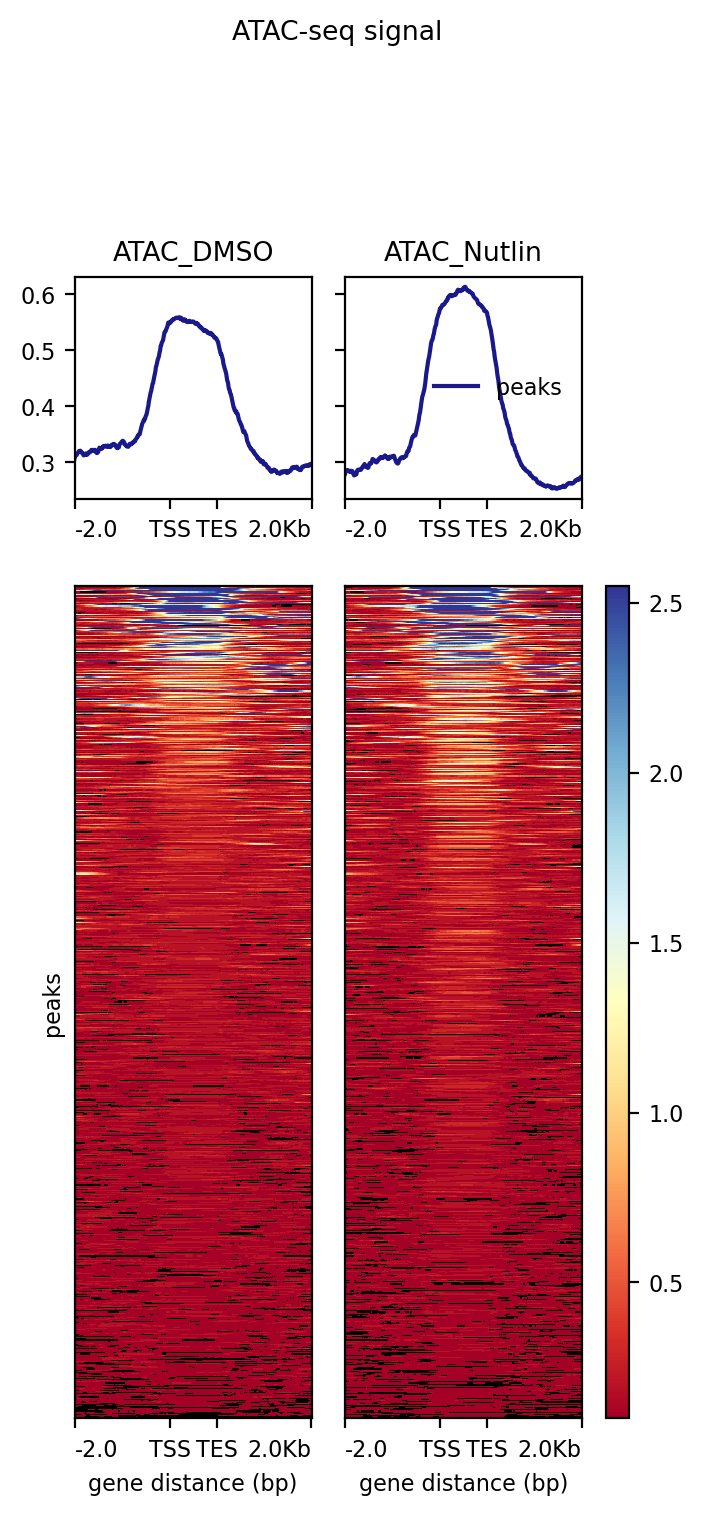
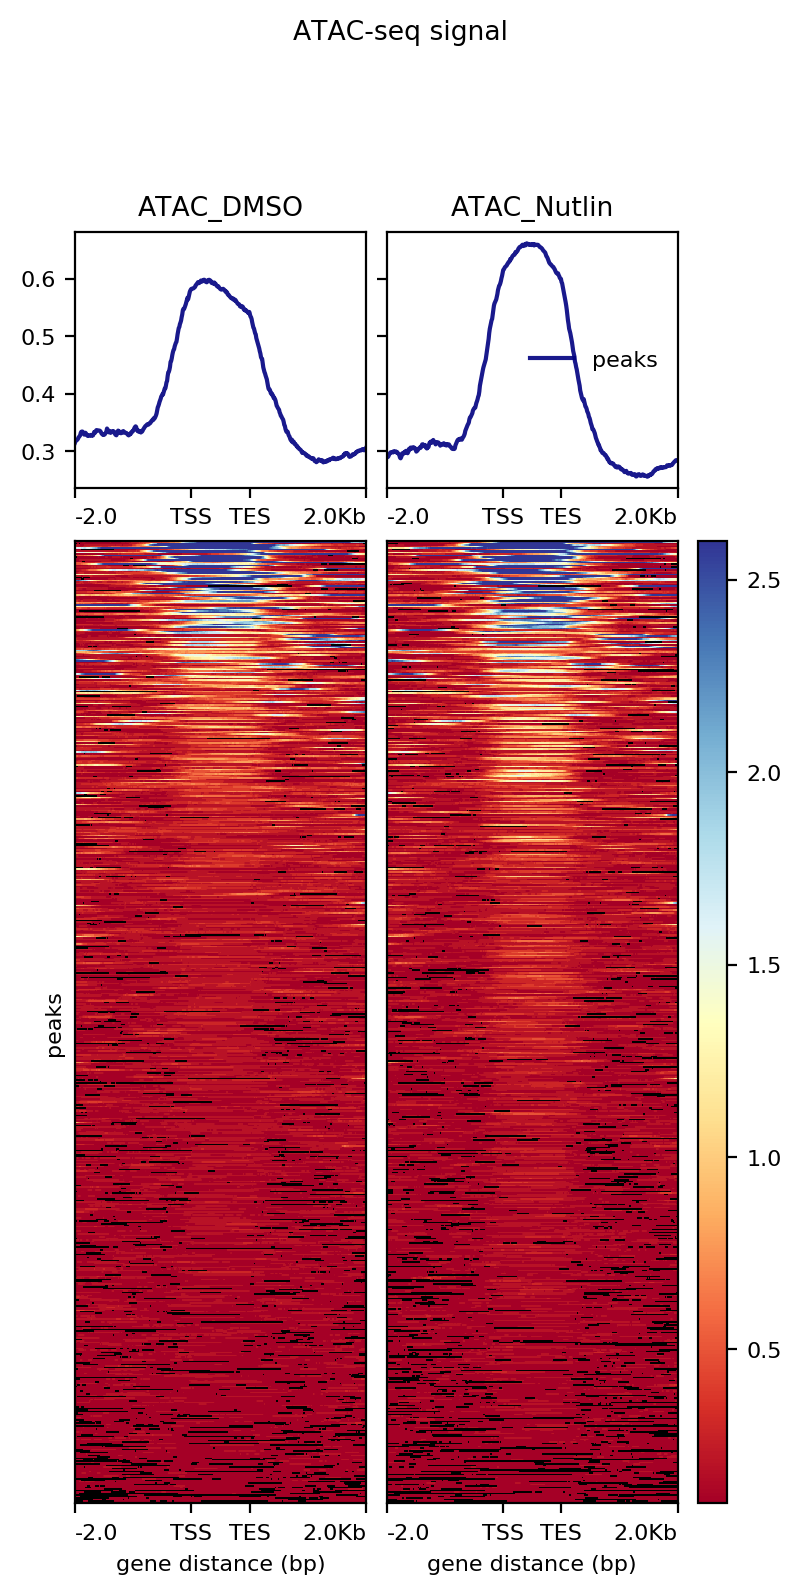

## Find differential ATAC-seq signal, genome-wide

We will use only the reads that map to chr19 for this exercise, for this analysis we need the bam files which we have already generated before.

Here, you can either use the files you have generated earlier in the analysis or use the provided bam file for chr19. Note that there might be differences in results.

You can use the code below to create symlinks to the already generated files if you prefer to use them.

In [46]:
ln -sf /data/teachers/data/bulk_atac_seq/p53_nutlin/data_generated/*chr19*.bam .

In [47]:
ls -lt *chr19*.bam

lrwxrwxrwx 1 u0160030 domain users       80 Oct 22 22:27 SRR1448793.chr19.bam -> /data/teachers/data/bulk_atac_seq/p53_nutlin/data_generated/SRR1448793.chr19.bam
lrwxrwxrwx 1 u0160030 domain users       80 Oct 22 22:27 SRR1448795.chr19.bam -> /data/teachers/data/bulk_atac_seq/p53_nutlin/data_generated/SRR1448795.chr19.bam
-rw-r--r-- 1 u0160030 domain users 34805039 Oct 22 21:30 SRR1448795.chr19.sorted.bam
-rw-r--r-- 1 u0160030 domain users 41486545 Oct 22 21:26 SRR1448793.chr19.sorted.bam


Reminder:

SRR1448793 -> ATAC-seq (DMSO)

SRR1448795 -> ATAC-seq (Nutlin-3a)

In [48]:
macs3 predictd -i SRR1448793.chr19.bam

INFO  @ 22 Oct 2025 22:27:38: [32 MB] # read alignment files... 
INFO  @ 22 Oct 2025 22:27:38: [32 MB] # read treatment tags... 
INFO  @ 22 Oct 2025 22:27:38: [52 MB] Detected format is: BAM 
INFO  @ 22 Oct 2025 22:27:38: [52 MB] * Input file is gzipped. 
INFO  @ 22 Oct 2025 22:27:39: [69 MB]  1000000 reads parsed 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] 1253351 reads have been read. 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] tag size is determined as 100 bps 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] # tag size = 100 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] # total tags in alignment file: 1253351 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] # Build Peak Model... 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] #2 looking for paired plus/minus strand peaks... 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] #2 Total number of paired peaks: 1186 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] #2 Model building with cross-correlation: Done 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] # finished! 
INFO  @ 22 Oct 2025 22:27:40: [69 MB] # pre

In [49]:
macs3 predictd -i SRR1448795.chr19.bam

INFO  @ 22 Oct 2025 22:27:41: [32 MB] # read alignment files... 
INFO  @ 22 Oct 2025 22:27:41: [32 MB] # read treatment tags... 
INFO  @ 22 Oct 2025 22:27:41: [52 MB] Detected format is: BAM 
INFO  @ 22 Oct 2025 22:27:41: [52 MB] * Input file is gzipped. 
INFO  @ 22 Oct 2025 22:27:42: [65 MB]  1000000 reads parsed 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] 1016443 reads have been read. 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] tag size is determined as 100 bps 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] # tag size = 100 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] # total tags in alignment file: 1016443 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] # Build Peak Model... 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] #2 looking for paired plus/minus strand peaks... 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] #2 Total number of paired peaks: 1333 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] #2 Model building with cross-correlation: Done 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] # finished! 
INFO  @ 22 Oct 2025 22:27:42: [65 MB] # pre

Predicted fragment sizes are 297bp and 296bp

Now we do peak calling per bam file, note that some arguments that we have used here are different that what you have seen before. This is due to our data being generated with a different method, ATAC-seq.

In [50]:
macs3 callpeak -B -t SRR1448793.chr19.bam -n DMSO --nomodel --format BAM --shift -100 --extsize 245

INFO  @ 22 Oct 2025 22:28:13: [32 MB] 
# Command line: callpeak -B -t SRR1448793.chr19.bam -n DMSO --nomodel --format BAM --shift -100 --extsize 245
# ARGUMENTS LIST:
# name = DMSO
# format = BAM
# ChIP-seq file = ['SRR1448793.chr19.bam']
# control file = None
# effective genome size = 2.91e+09
# band width = 300
# model fold = [5, 50]
# qvalue cutoff = 5.00e-02
# The maximum gap between significant sites is assigned as the read length/tag size.
# The minimum length of peaks is assigned as the predicted fragment length "d".
# Larger dataset will be scaled towards smaller dataset.
# Range for calculating regional lambda is: 10000 bps
# Broad region calling is off
# Paired-End mode is off
 
INFO  @ 22 Oct 2025 22:28:13: [32 MB] #1 read tag files... 
INFO  @ 22 Oct 2025 22:28:13: [32 MB] #1 read treatment tags... 
INFO  @ 22 Oct 2025 22:28:15: [71 MB]  1000000 reads parsed 
INFO  @ 22 Oct 2025 22:28:15: [74 MB] 1253351 reads have been read. 
INFO  @ 22 Oct 2025 22:28:15: [74 MB] #1 tag si

In [51]:
macs3 callpeak -B -t SRR1448795.chr19.bam -n nutlin --nomodel --format BAM --shift -100 --extsize 245

INFO  @ 22 Oct 2025 22:28:20: [32 MB] 
# Command line: callpeak -B -t SRR1448795.chr19.bam -n nutlin --nomodel --format BAM --shift -100 --extsize 245
# ARGUMENTS LIST:
# name = nutlin
# format = BAM
# ChIP-seq file = ['SRR1448795.chr19.bam']
# control file = None
# effective genome size = 2.91e+09
# band width = 300
# model fold = [5, 50]
# qvalue cutoff = 5.00e-02
# The maximum gap between significant sites is assigned as the read length/tag size.
# The minimum length of peaks is assigned as the predicted fragment length "d".
# Larger dataset will be scaled towards smaller dataset.
# Range for calculating regional lambda is: 10000 bps
# Broad region calling is off
# Paired-End mode is off
 
INFO  @ 22 Oct 2025 22:28:20: [32 MB] #1 read tag files... 
INFO  @ 22 Oct 2025 22:28:20: [32 MB] #1 read treatment tags... 
INFO  @ 22 Oct 2025 22:28:22: [77 MB]  1000000 reads parsed 
INFO  @ 22 Oct 2025 22:28:22: [77 MB] 1016443 reads have been read. 
INFO  @ 22 Oct 2025 22:28:22: [77 MB] #1 ta

In [52]:
grep -E "tags after filtering in treatment|tags after filtering in control" nutlin_peaks.xls

# tags after filtering in treatment: 822211


In [53]:
grep -E "tags after filtering in treatment|tags after filtering in control" DMSO_peaks.xls

# tags after filtering in treatment: 1023152


In [54]:
ls -lt *.bdg

-rw-r--r-- 1 u0160030 domain users 50242277 Oct 22 22:28 nutlin_control_lambda.bdg
-rw-r--r-- 1 u0160030 domain users 49728064 Oct 22 22:28 nutlin_treat_pileup.bdg
-rw-r--r-- 1 u0160030 domain users 62218411 Oct 22 22:28 DMSO_control_lambda.bdg
-rw-r--r-- 1 u0160030 domain users 61498614 Oct 22 22:28 DMSO_treat_pileup.bdg


In [56]:
macs3 bdgdiff \
    --t1 nutlin_treat_pileup.bdg \
    --c1 nutlin_control_lambda.bdg \
    --t2 DMSO_treat_pileup.bdg \
    --c2 DMSO_control_lambda.bdg \
    --d1 822211 \
    --d2 1023152 \
    -g 60 \
    -l 120 \
    --o-prefix diff_nutlin_vs_DMSO

INFO  @ 22 Oct 2025 22:28:49: [32 MB] Read and build treatment 1 bedGraph... 
INFO  @ 22 Oct 2025 22:28:50: [44 MB] Read and build control 1 bedGraph... 
INFO  @ 22 Oct 2025 22:28:51: [56 MB] Read and build treatment 2 bedGraph... 
INFO  @ 22 Oct 2025 22:28:51: [72 MB] Read and build control 2 bedGraph... 
INFO  @ 22 Oct 2025 22:28:57: [277 MB] Write peaks... 
INFO  @ 22 Oct 2025 22:28:57: [277 MB] Done 


In [57]:
ls -lt *.bed | head

-rw-r--r-- 1 u0160030 domain users 106999 Oct 22 22:28 diff_nutlin_vs_DMSO_c3.0_common.bed
-rw-r--r-- 1 u0160030 domain users   3226 Oct 22 22:28 diff_nutlin_vs_DMSO_c3.0_cond1.bed
-rw-r--r-- 1 u0160030 domain users    492 Oct 22 22:28 diff_nutlin_vs_DMSO_c3.0_cond2.bed
-rw-r--r-- 1 u0160030 domain users  74409 Oct 22 22:28 nutlin_summits.bed
-rw-r--r-- 1 u0160030 domain users  75923 Oct 22 22:28 DMSO_summits.bed
-rw-r--r-- 1 u0160030 domain users  18453 Oct 22 22:22 p53-all_peaks.bed


In [58]:
wc -l *.bed

  1771 diff_nutlin_vs_DMSO_c3.0_common.bed
    54 diff_nutlin_vs_DMSO_c3.0_cond1.bed
     8 diff_nutlin_vs_DMSO_c3.0_cond2.bed
  1659 DMSO_summits.bed
  1558 nutlin_summits.bed
   774 p53-all_peaks.bed
  5824 total


In [59]:
cat diff_nutlin_vs_DMSO_c3.0_cond1.bed | sort -k 5,5gr | head

chr19	16912057	16912259	diff_nutlin_vs_DMSO_cond1_17	6.29167
chr19	18215357	18215482	diff_nutlin_vs_DMSO_cond1_19	6.11009
chr14	99456388	99456552	diff_nutlin_vs_DMSO_cond1_1	6
chr20	31702986	31703151	diff_nutlin_vs_DMSO_cond1_51	6
chr5	49551421	49551619	diff_nutlin_vs_DMSO_cond1_52	6
chr8	43772177	43772408	diff_nutlin_vs_DMSO_cond1_53	6
chr19	12633279	12633445	diff_nutlin_vs_DMSO_cond1_12	5.59664
chr19	2291344	2291533	diff_nutlin_vs_DMSO_cond1_4	5.37433
chr19	29396722	29396854	diff_nutlin_vs_DMSO_cond1_26	5.17969
chr19	14229413	14229597	diff_nutlin_vs_DMSO_cond1_13	4.95604


Let's visualize them all together

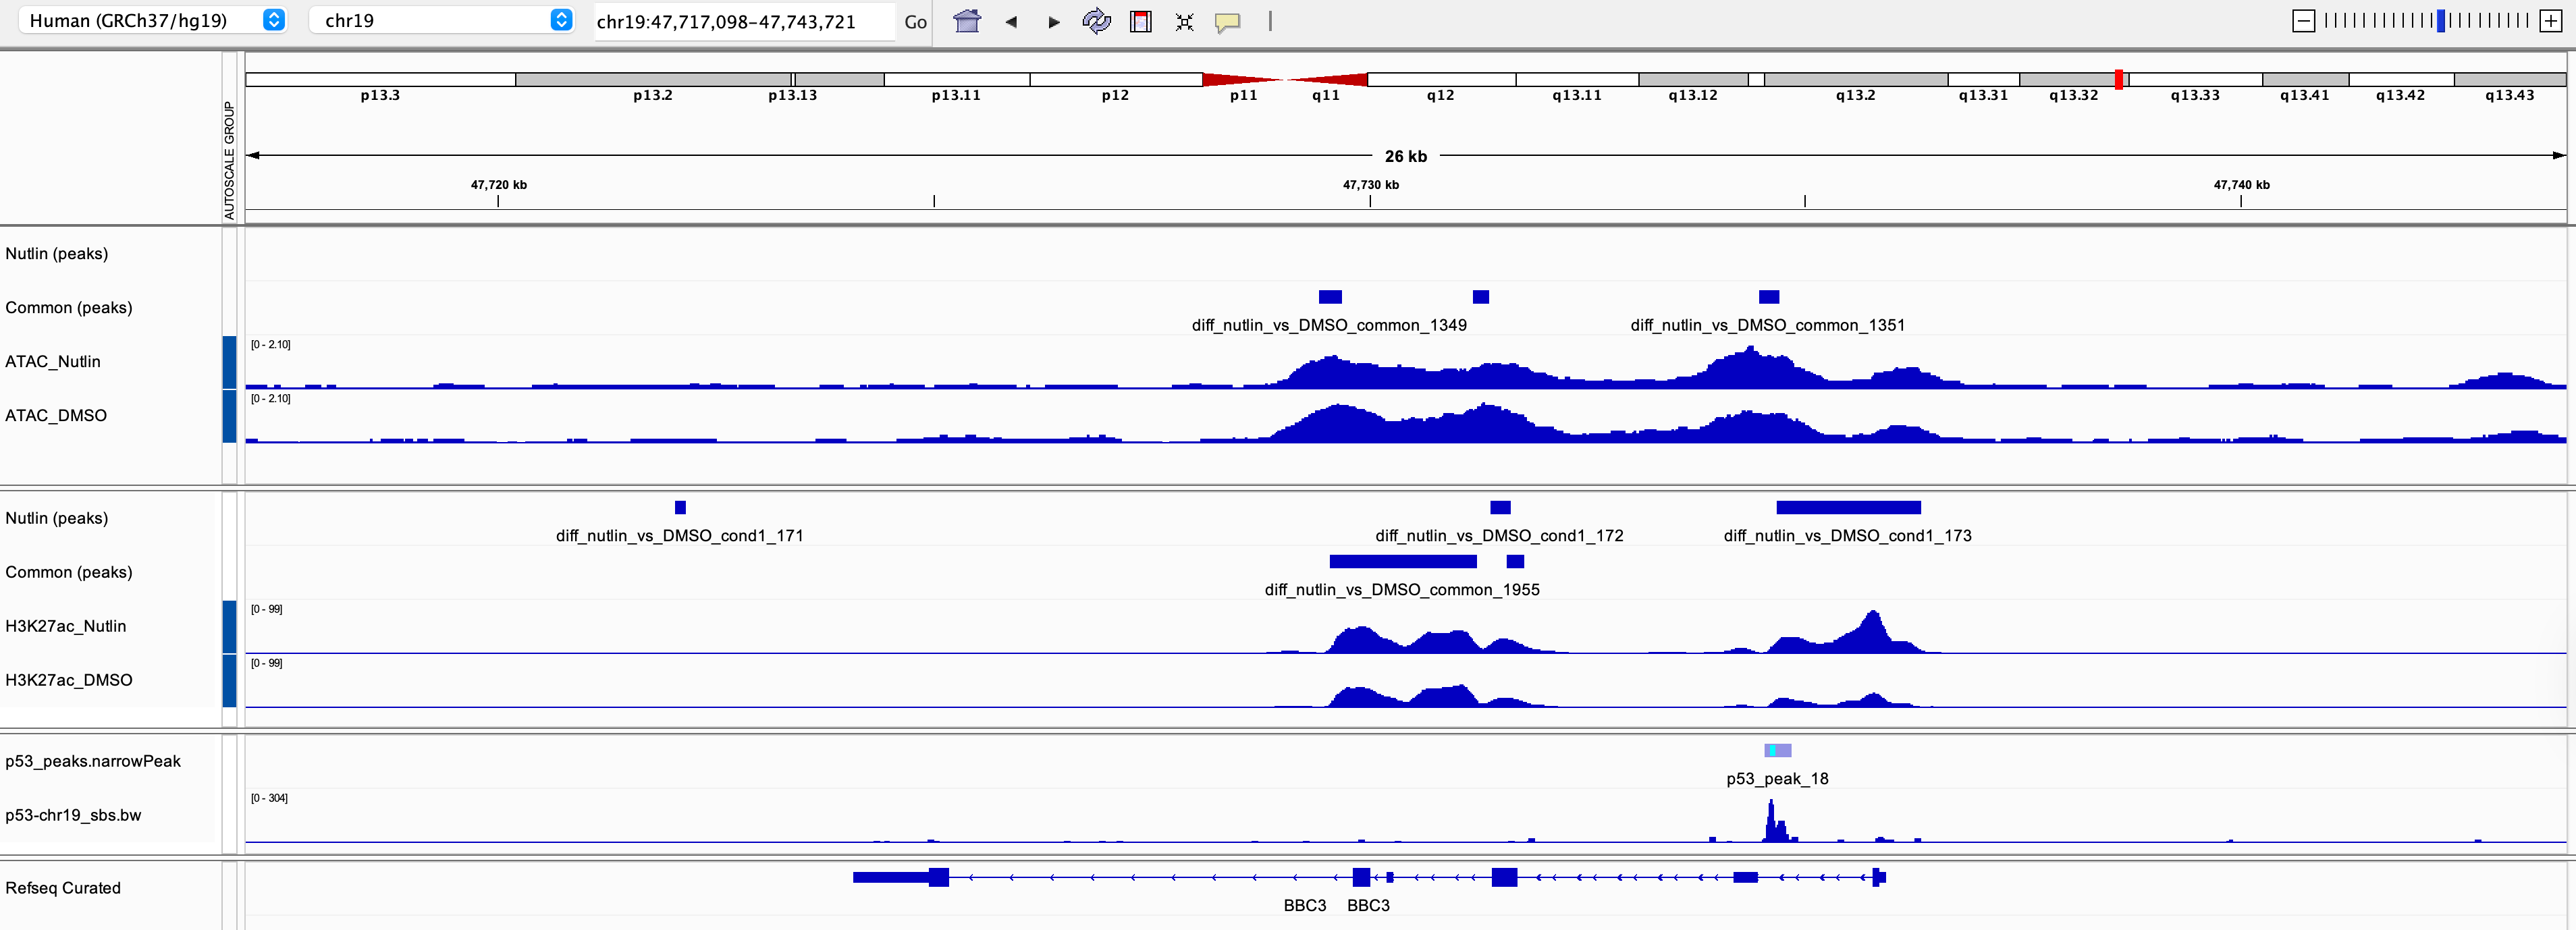

We notice that differentially accessible regions in DMSO vs Nutlin-treated samples do not have as strong ATAC signal difference as what we observe in H3K27Ac (compare the called peaks too). What might be the reasons for this?

Finally, you can continue using this differentially accessible regions with additional functional/motif analysis as we will see in another notebook.